# 1. Import Libraries 

In [1]:
import tensorflow as tf
import matplotlib.pyplot as plt 
# set default grayscale to show image by plt
plt.rc('image', cmap='gray')
plt.rc('figure', autolayout=True)

# 2.Load and preprocess the image 

In [2]:
image_path = "../data/images/image1.png"
image = tf.io.read_file(image_path)
image.shape

TensorShape([])

In [3]:
# Đọc file ảnh từ dạng byte thô -> tensor số 
image = tf.io.decode_jpeg(image, channels=1) 
# Resize ảnh về kích thước 300x300  
image = tf.image.resize(image, [900, 900])
# Chuyển pixel 0-255 về khoảng 0.0 - 1.0 
image = tf.image.convert_image_dtype(image, tf.float32)
image = image/255
print("Original Image Shape:", image.shape)

Original Image Shape: (900, 900, 1)


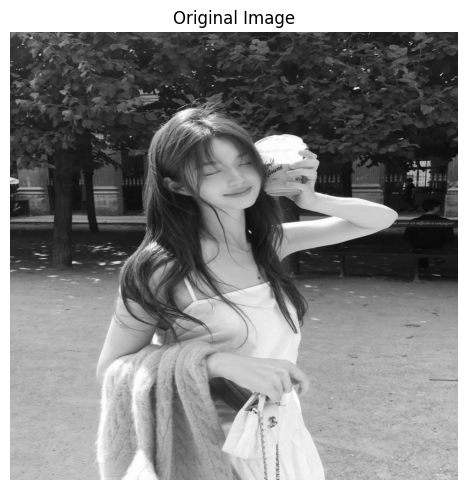

In [4]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(image))
plt.title("Original Image")
plt.axis('off')
plt.show()

image = tf.expand_dims(image, axis=0)

# 3. Define Convolution Kernel 

In [5]:
kernel = tf.constant([
    [-1,0,-1], 
    [-1,8,-1],
    [-1,-1,-1]
], dtype=tf.float32)

In [6]:
kernel

<tf.Tensor: shape=(3, 3), dtype=float32, numpy=
array([[-1.,  0., -1.],
       [-1.,  8., -1.],
       [-1., -1., -1.]], dtype=float32)>

In [7]:
kernel=tf.reshape(kernel, [3,3,1,1])
kernel

<tf.Tensor: shape=(3, 3, 1, 1), dtype=float32, numpy=
array([[[[-1.]],

        [[ 0.]],

        [[-1.]]],


       [[[-1.]],

        [[ 8.]],

        [[-1.]]],


       [[[-1.]],

        [[-1.]],

        [[-1.]]]], dtype=float32)>

# 4. Apply Convolution Layer

In [8]:

conv_output = tf.nn.conv2d(
    input=image, 
    filters=kernel,
    strides=[1,1,1,1], 
    padding='SAME'
)
print('After Convolution Shape: ', conv_output.shape)

After Convolution Shape:  (1, 900, 900, 1)


## 📊 Stride Explanation

| Vị trí      | Giá trị | Tại sao luôn = 1?                                   |
| ----------- | ------- | --------------------------------------------------- |
| [0] batch   | 1       | Bắt buộc = 1, không được bỏ qua ảnh nào trong batch |
| [1] height  | 1       | Trượt 1 pixel theo chiều dọc                        |
| [2] width   | 1       | Trượt 1 pixel theo chiều ngang                      |
| [3] channel | 1       | Bắt buộc = 1, không được bỏ qua kênh nào            |


In [9]:
conv_output

<tf.Tensor: shape=(1, 900, 900, 1), dtype=float32, numpy=
array([[[[2.1683054 ],
         [1.1834013 ],
         [1.108762  ],
         ...,
         [0.6327467 ],
         [0.68900687],
         [1.1383331 ]],

        [[1.9503524 ],
         [0.36189464],
         [0.28273958],
         ...,
         [0.20595771],
         [0.25905624],
         [0.94567037]],

        [[1.9433557 ],
         [0.24572581],
         [0.24005285],
         ...,
         [0.15833509],
         [0.21290544],
         [0.894047  ]],

        ...,

        [[2.8669412 ],
         [0.74848247],
         [0.80066717],
         ...,
         [0.7144954 ],
         [0.7706821 ],
         [2.973022  ]],

        [[3.1230152 ],
         [0.8674747 ],
         [0.89566785],
         ...,
         [0.6982477 ],
         [0.50911874],
         [2.4462056 ]],

        [[4.6434007 ],
         [3.0076146 ],
         [3.0238857 ],
         ...,
         [2.766308  ],
         [2.6614625 ],
         [4.2776093 ]]]], sha

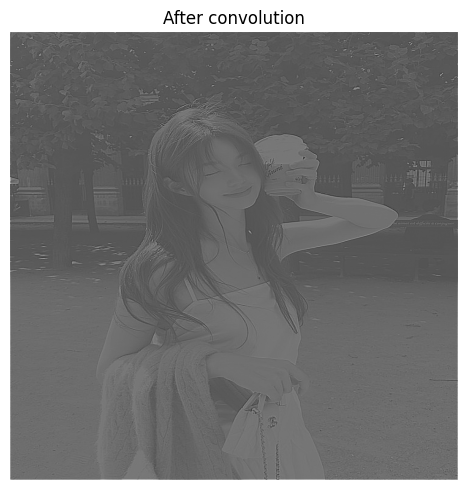

In [10]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(conv_output))
plt.title("After convolution")
plt.axis('off')
plt.show()

In [11]:
conv_output1 = tf.nn.conv2d(
    input=image, 
    filters=kernel,
    strides=[1,2,2,1], 
    padding='SAME'
)
print('After Convolution Shape: ', conv_output1.shape)

After Convolution Shape:  (1, 450, 450, 1)


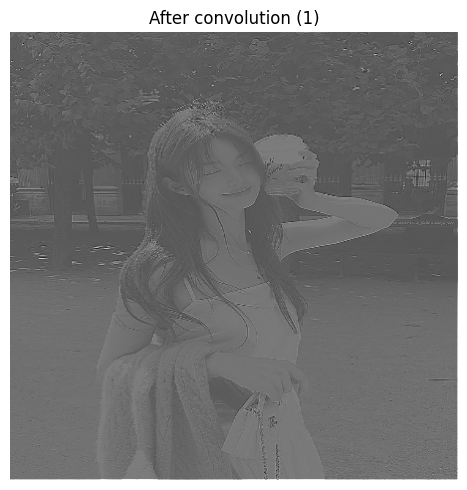

In [12]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(conv_output1))
plt.title("After convolution (1)")
plt.axis('off')
plt.show()

# 5. Apply ReLU Activation Function

After ReLU Shape:  (1, 900, 900, 1)


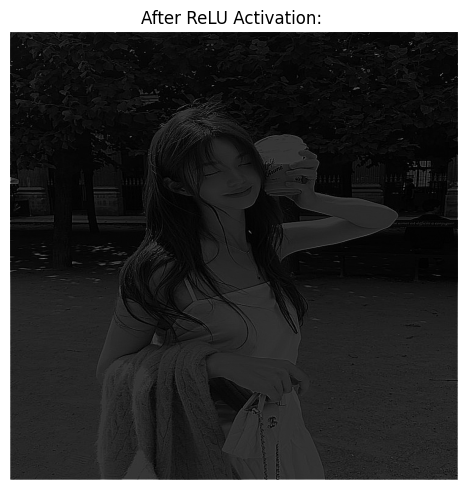

In [13]:
relu_output = tf.nn.relu(conv_output)
print("After ReLU Shape: ", relu_output.shape)
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(relu_output))
plt.title("After ReLU Activation: ")
plt.axis('off')
plt.show()

After ReLU Shape:  (1, 450, 450, 1)


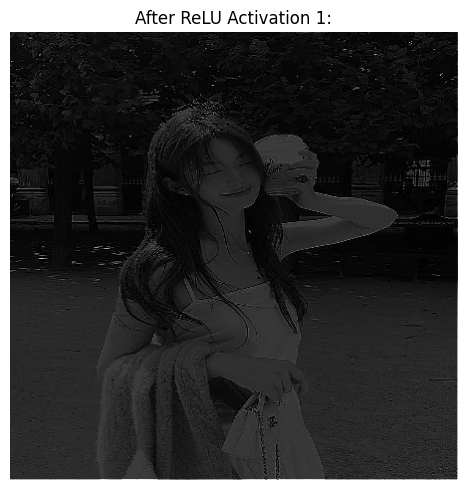

In [14]:
relu_output1 = tf.nn.relu(conv_output1)
print("After ReLU Shape: ", relu_output1.shape)
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(relu_output1))
plt.title("After ReLU Activation 1:")
plt.axis('off')
plt.show()

# 6. Apply Max pooling layer 

In [15]:
pool_output = tf.nn.max_pool2d(
    input=relu_output, 
    ksize=[1,2,2,1],
    strides=[1,2,2,1],
    padding='SAME'
)
print("After pooling Shape:", pool_output.shape)

After pooling Shape: (1, 450, 450, 1)


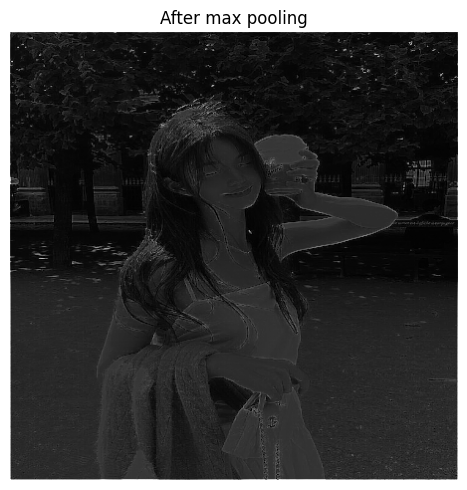

In [16]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(pool_output))
plt.title("After max pooling")
plt.axis('off')
plt.show()

In [17]:
pool_output1 = tf.nn.max_pool2d(
    input=relu_output1,
    ksize=[1,2,2,1],
    strides=[1,2,2,1],
    padding='SAME'
)

print("After pooling shape", pool_output1.shape)

After pooling shape (1, 225, 225, 1)


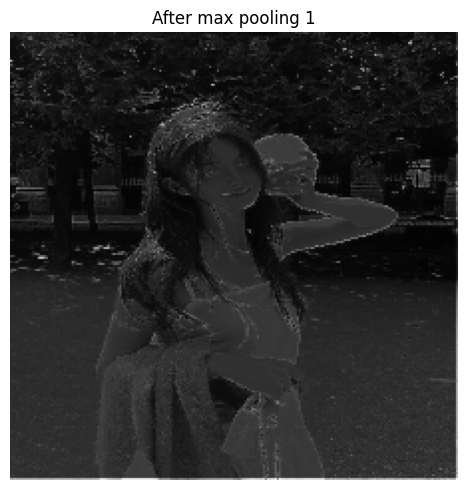

In [18]:
plt.figure(figsize=(5,5))
plt.imshow(tf.squeeze(pool_output1))
plt.title("After max pooling 1")
plt.axis('off')
plt.show()

# 7. Apply Flatten Layer

In [19]:
flatten_layer = tf.keras.layers.Flatten() 
flatten_output = flatten_layer(pool_output)

print("After Flatten Shape: ", flatten_output.shape)
print("First 20 flattened Values: ")
print(flatten_output.numpy()[0][:20])

After Flatten Shape:  (1, 202500)
First 20 flattened Values: 
[2.1683054 1.1302111 1.6731744 1.53511   1.6232831 1.4929183 1.4660763
 1.3750284 1.195528  1.3271556 1.3088789 1.4207305 1.599928  1.5875828
 1.3620195 1.8802164 1.8734117 1.4768703 1.3046658 1.3693012]


# 8. Add Fully Connected (Dense) Layer

In [20]:
dense_layer = tf.keras.layers.Dense(
    units=64, 
    activation='relu'
)

dense_output = dense_layer(flatten_output)
print("After fully connected layer shape: ", dense_output)

After fully connected layer shape:  tf.Tensor(
[[0.12509263 0.         0.         0.         0.         0.30631983
  0.8646438  0.4892894  0.40478185 0.         1.1741126  0.23135796
  0.         1.8163407  0.9788     0.9825517  0.         0.
  1.0295953  1.2177527  0.         0.         1.4003456  1.11273
  0.         0.7040591  0.9082093  0.         0.         0.
  0.256995   0.4584034  0.62908244 0.         0.         0.
  0.21795297 1.5282837  0.37208667 0.         0.8102083  0.1496826
  0.18237261 0.9501127  0.4571132  2.3410559  0.         0.1244552
  0.6717243  0.         0.         0.         0.35170263 0.
  0.8188881  0.9125006  0.         0.         0.         0.5747471
  1.8020455  1.10995    0.76979387 0.31147102]], shape=(1, 64), dtype=float32)
